# Chapitre 7 - Exercices 7.1 à 7.4

Ce notebook traite les quatre premiers exercices du chapitre, centrés sur l'atomicité, la
durabilité et l'isolation faible :

- **7.1** : journal, fsync et validation groupée (calculs, puis injection de pannes
  dans un journal mal ordonné et dans un journal sans somme de contrôle) ;
- **7.2** : diagnostiquer six historiques (anomalie et niveau minimal qui l'empêche) ;
- **7.3** : visibilité MVCC à la main, et gonflement des tables par une transaction
  longue ;
- **7.4** : le « paradoxe des anniversaires » des mises à jour perdues, et le coût du
  *compare-and-set*.

In [1]:
import itertools
import math
import zlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import transactions as tr
from ddia.transactions import R, W, S, INC, RFU, run, plot_history, Engine, LEVEL_LABELS
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 7.1 : journal, fsync et validation groupée

**Énoncé.**

1. Un journal est écrit sur un disque dont un `fsync` coûte 4 ms et dont le débit
   séquentiel est de 200 Mo/s. Chaque transaction ajoute 300 octets au journal. Quel est
   le débit maximal de validations durables si chaque transaction fait son propre
   `fsync` ? Avec des lots de 32 ? À partir de quelle taille de lot le débit séquentiel
   devient-il la limite ?
2. Politique de validation groupée : dès qu'un `fsync` se termine, on en lance un nouveau
   pour toutes les transactions arrivées entre-temps. Les transactions arrivent selon un
   processus de Poisson de taux $\lambda$. Simuler la latence moyenne de validation et la
   taille moyenne des lots en fonction de $\lambda$.
3. Un développeur « optimise » le moteur en écrivant le record de validation **avant**
   les données (pour libérer le client plus vite). Montrer par injection exhaustive de
   pannes que l'atomicité est perdue.
4. Un autre supprime les sommes de contrôle. Montrer qu'une ligne tronquée peut alors être
   relue comme une écriture valide mais **fausse**.

**Rappels.** Atomicité = données puis record de validation, chacun protégé par une somme
de contrôle ; durabilité = `fsync` avant l'accusé ; validation groupée (cours 1, sections
3 et 4 ; sections *Atomicity* et *Durability*).

**Solution.**

*1.* Un `fsync` par transaction : $1 / 4\,\text{ms} = 250$ transactions par seconde. Avec
des lots de $b$ transactions, un `fsync` écrit $300\,b$ octets en
$t(b) = 4\,\text{ms} + 300\,b / (200 \cdot 10^6)\,\text{s}$, soit un débit
$b / t(b)$ : pour $b = 32$, $t = 4{,}048$ ms et le débit vaut environ 7 900 tx/s. Le
transfert devient comparable à la latence du `fsync` quand
$300\,b / 200\cdot 10^6 = 4\cdot 10^{-3}$, soit $b \approx 2\,667$ (débit
$\approx 333\,000$ tx/s, la moitié de l'asymptote $200\cdot10^6/300 \approx 667\,000$).

*2.* Simulation ci-dessous. Intuition : à faible charge, chaque transaction attend la fin
du `fsync` en cours (en moyenne la moitié) puis le sien, soit une latence entre 4 et 8 ms ;
à forte charge, les lots grossissent proportionnellement à $\lambda$ et la latence reste
bornée (environ 2 `fsync`) : la validation groupée **absorbe** la charge au lieu de saturer.

*3. et 4.* Code ci-dessous.

lot de    1 : fsync de 4.002 ms ->       250 tx/s
lot de   32 : fsync de 4.048 ms ->     7 905 tx/s
lot de 2667 : fsync de 8.001 ms ->   333 354 tx/s


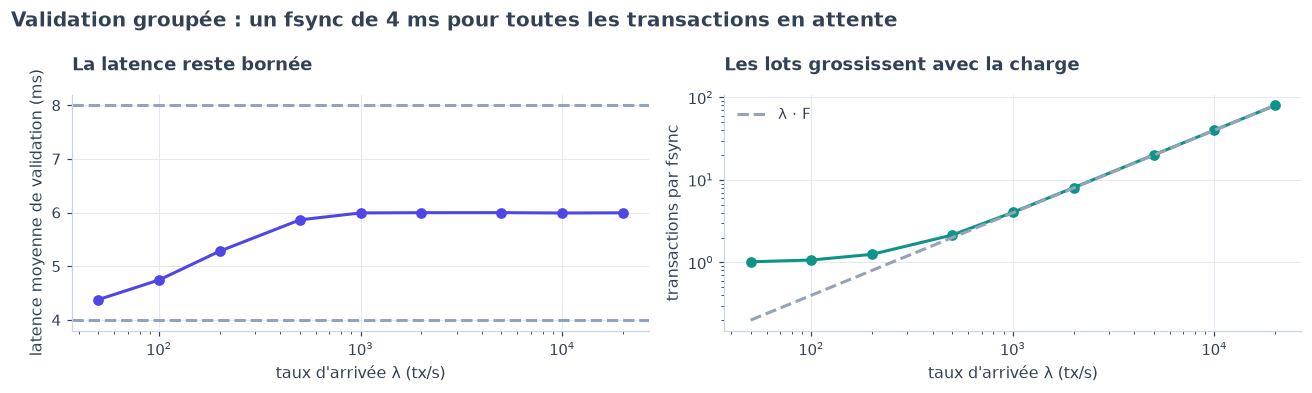

In [2]:
F, BW, REC = 4e-3, 200e6, 300
for b in [1, 32, 2667]:
    t = F + REC * b / BW
    print(f"lot de {b:>4} : fsync de {t * 1e3:.3f} ms -> {b / t:>9,.0f} tx/s".replace(",", " "))


def validation_groupee(lam, F=4e-3, n=20000, seed=0):
    g = np.random.default_rng(seed)
    arrivees = np.cumsum(g.exponential(1 / lam, n))
    lat, lots = [], []
    t_libre, i = 0.0, 0
    while i < n:
        debut = max(t_libre, arrivees[i])          # le disque est libre et quelqu'un attend
        j = np.searchsorted(arrivees, debut, side="right")
        fin = debut + F
        lat.extend(fin - arrivees[i:j])
        lots.append(j - i)
        i, t_libre = j, fin
    return np.mean(lat) * 1e3, np.mean(lots)


lams = [50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000]
sim = pd.DataFrame([dict(λ=l, latence_ms=validation_groupee(l)[0], lot_moyen=validation_groupee(l)[1]) for l in lams])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(sim["λ"], sim["latence_ms"], marker="o", color=INDIGO)
axes[0].axhline(4, color=GRAY, ls="--"); axes[0].axhline(8, color=GRAY, ls="--")
axes[0].set_ylabel("latence moyenne de validation (ms)")
axes[0].set_title("La latence reste bornée")
axes[1].plot(sim["λ"], sim["lot_moyen"], marker="o", color=TEAL)
axes[1].plot(sim["λ"], sim["λ"] * 4e-3, color=GRAY, ls="--", label="λ · F")
axes[1].set_yscale("log")
axes[1].set_ylabel("transactions par fsync")
axes[1].set_title("Les lots grossissent avec la charge")
axes[1].legend()
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("taux d'arrivée λ (tx/s)")
finish(fig, "Validation groupée : un fsync de 4 ms pour toutes les transactions en attente")
plt.show()

La latence passe d'environ 4 ms (charge nulle : on attend seulement son `fsync`) à un
plateau proche de 6 ms (moitié du `fsync` en cours, puis le sien), et la taille des lots
suit $\lambda F$. Sans regroupement, le système saturerait dès 250 tx/s.

Passons aux journaux défectueux. D'abord le record de validation écrit **en tête** de
chaque transaction : la récupération applique alors les écritures de toute transaction
dont elle a vu le record `C`.

In [3]:
def enc(*champs, crc=True):
    corps = " ".join(str(c) for c in champs)
    return (f"{corps} {zlib.crc32(corps.encode()):08x}\n" if crc else f"{corps}\n").encode()


def journal_validation_en_tete(txs):
    out = bytearray()
    for txid, ecr in txs:
        out += enc(txid, "C", "-", "-")
        for k, v in ecr:
            out += enc(txid, "W", k, v)
    return bytes(out)


def recupere_tete(init, log):
    etat, valides = dict(init), set()
    for ligne in log.split(b"\n"):
        try:
            *ch, crc = ligne.decode().split(" ")
            if len(ch) != 4 or int(crc, 16) != zlib.crc32(" ".join(ch).encode()):
                break
        except ValueError:
            break
        txid, kind, k, v = ch
        if kind == "C":
            valides.add(txid)
        elif txid in valides:
            etat[k] = int(v)
    return etat


init, txs = tr.transfer_txs(4, seed=3)
total = sum(init.values())
bon = tr.wal_encode(txs)
mauvais = journal_validation_en_tete(txs)
viol_bon = sum(sum(tr.wal_recover(init, bon[:b])[0].values()) != total for b in range(len(bon) + 1))
viol_mauvais = sum(sum(recupere_tete(init, mauvais[:b]).values()) != total for b in range(len(mauvais) + 1))
print(f"données puis validation : {viol_bon} point(s) de panne violent l'invariant sur {len(bon) + 1}")
print(f"validation en tête      : {viol_mauvais} point(s) de panne violent l'invariant sur {len(mauvais) + 1}")

données puis validation : 0 point(s) de panne violent l'invariant sur 217
validation en tête      : 76 point(s) de panne violent l'invariant sur 217


Avec le record en tête, toute panne survenant entre le `C` et la dernière écriture d'une
transaction laisse une transaction « validée » mais incomplète (un débit sans crédit) :
plus d'un tiers des points de panne (76 sur 217) violent l'invariant.

Ensuite, sans somme de contrôle : une ligne tronquée en plein milieu d'un nombre reste
syntaxiquement valide.

In [4]:
txs_simple = [(1, [("A", 1234), ("B", -1234)])]
sans_crc = b"".join(enc(t, "W", k, v, crc=False) for t, w in txs_simple for k, v in w) + enc(1, "C", "-", "-", crc=False)
print(sans_crc.decode())
coupe = sans_crc[:9]
print("préfixe écrit avant la panne :", coupe)
champs = coupe.decode().split()
print("relu sans somme de contrôle :", champs, "-> A vaudrait", champs[3], "au lieu de 1234")
avec = tr.wal_encode([(1, [("A", 1234)])])
print("avec somme de contrôle, la même troncature est rejetée :",
      tr.wal_recover({"A": 0}, avec[:9]))

1 W A 1234
1 W B -1234
1 C - -

préfixe écrit avant la panne : b'1 W A 123'
relu sans somme de contrôle : ['1', 'W', 'A', '123'] -> A vaudrait 123 au lieu de 1234
avec somme de contrôle, la même troncature est rejetée : ({'A': 0}, [])


Sans somme de contrôle, `1 W A 123` est une écriture parfaitement lisible... et fausse.
Ici le record `C` manque, donc elle ne serait pas appliquée ; mais une troncature de la
**valeur** d'un enregistrement suivi d'un `C` (secteurs écrits dans le désordre par le
disque, ce qui arrive) produirait une donnée corrompue validée. La somme de contrôle rend
toute ligne incomplète ou corrompue détectable.

> **À retenir.** Un journal est atomique grâce à **deux** détails : l'ordre (données puis
> validation) et l'intégrité de chaque enregistrement (somme de contrôle). La validation
> groupée rend le `fsync` abordable en partageant son coût.

## Exercice 7.2 : diagnostiquer six historiques

**Énoncé.** Pour chacun des scénarios suivants, nommer l'anomalie, dire quel est le niveau
d'isolation le plus faible qui l'empêche (parmi *read uncommitted*, *read committed*,
snapshot isolation à la PostgreSQL, sérialisable), puis vérifier sur le moteur. La
notation `r1(x)` signifie « la transaction 1 lit x », `c1` « 1 valide », `a1` « 1 annule ».

| | scénario | historique |
|---|---|---|
| a | deux caisses décrémentent le stock d'un article (10) | `r1(s) r2(s) w1(s=9) c1 w2(s=9) c2` |
| b | un inventaire additionne deux entrepôts pendant un transfert de 5 unités | `r1(e1) r2(e1) w2(e1) r2(e2) w2(e2) c2 r1(e2) c1` |
| c | une remise est appliquée puis annulée ; un client lit le prix entre-temps | `w1(p=80) r2(p) a1 c2` |
| d | deux promotions écrivent chacune deux lignes (bannière, prix) | `w1(b) w2(b) w2(p) c2 w1(p) c1` |
| e | deux comptes joints (somme ≥ 0) : chaque titulaire retire 150 de son compte quand le total est 200 | `r1(a,b) r2(a,b) w1(a) w2(b) c1 c2` |
| f | un atelier limité à 3 inscrits en compte 2 ; deux nouvelles inscriptions | `r1(count) r2(count) ins1 ins2 c1 c2` |

**Rappels.** Lecture sale et écriture sale (*Read Committed*), lecture biaisée (*Snapshot
Isolation and Repeatable Read*), mise à jour perdue (*Preventing Lost Updates*), write
skew et fantômes (*Write Skew and Phantoms*) ; récapitulatif expérimental au cours 3,
section 10.

**Solution.**

- **a.** Mise à jour perdue (le stock devrait valoir 8). *Read committed* ne l'empêche pas
  (la seconde écriture n'est pas sale) ; la snapshot isolation de PostgreSQL l'empêche en
  abandonnant la transaction 2.
- **b.** Lecture biaisée : l'inventaire lit e1 avant le transfert et e2 après, et compte 5
  unités de trop ou de moins. Empêchée par la snapshot isolation (l'inventaire lit un
  instantané).
- **c.** Lecture sale d'une valeur jamais validée. Empêchée par *read committed*.
- **d.** Écriture sale : la bannière de la promotion 2 et le prix de la promotion 1.
  Empêchée dès *read uncommitted* (verrous d'écriture).
- **e.** Write skew : chacun voit 200, retire 150 d'un compte différent ; le total devient
  -100. Seul le niveau sérialisable l'empêche.
- **f.** Fantôme provoquant un write skew : les deux comptent 2 inscrits et insèrent une
  ligne nouvelle : 4 inscrits. Seul le niveau sérialisable l'empêche (et `FOR UPDATE` sur
  les inscriptions existantes **pourrait** aider, voir l'exercice 7.5).

**Vérification.** On code chaque scénario, on l'exécute à chaque niveau, et on cherche le
niveau le plus faible où l'anomalie n'apparaît pas.

In [5]:
def p_dec():
    s = yield R("s")
    yield W("s", s - 1)


def p_inventaire():
    a = yield R("e1")
    b = yield R("e2")
    return a + b


def p_transfert():
    a = yield R("e1")
    yield W("e1", a - 5)
    b = yield R("e2")
    yield W("e2", b + 5)


def p_remise():
    yield W("p", 80)
    yield tr.ABORT


def p_lit_prix():
    yield R("p")


def p_promo(n):
    def prog():
        yield W("b", f"bannière{n}")
        yield W("p", f"prix{n}")
    return prog


def p_retrait(moi):
    def prog():
        tot = yield S(lambda k, v: k in ("a", "b"), "total")
        if sum(tot.values()) - 150 >= 0:
            yield W(moi, tot[moi] - 150)
    return prog


def p_inscription(qui):
    def prog():
        ins = yield S(lambda k, v: k.startswith("ins:"), "inscrits")
        if len(ins) < 3:
            yield W(f"ins:{qui}", True)
    return prog


cas = {
    "a. stock": ({"s": 10}, {"1": p_dec, "2": p_dec}, "121212", lambda r: r.committed == ["1", "2"] and r.final["s"] == 9),
    "b. inventaire": ({"e1": 50, "e2": 50}, {"1": p_inventaire, "2": p_transfert}, "12222211",
                      lambda r: sum(r.reads["1"]) != 100),
    "c. remise annulée": ({"p": 100}, {"1": p_remise, "2": p_lit_prix}, "1212", lambda r: r.reads["2"] == [80]),
    "d. promotions": ({"b": None, "p": None}, {"1": p_promo(1), "2": p_promo(2)}, "122211",
                      lambda r: r.final["b"][-1] != r.final["p"][-1]),
    "e. comptes joints": ({"a": 100, "b": 100}, {"1": p_retrait("a"), "2": p_retrait("b")}, "121212",
                          lambda r: r.final["a"] + r.final["b"] < 0),
    "f. atelier": ({"ins:x": True, "ins:y": True}, {"1": p_inscription("u"), "2": p_inscription("v")}, "121212",
                   lambda r: len(r.final) > 3),
}
ordre_niv = ["read_uncommitted", "read_committed", "snapshot", "serializable_ssi"]
lignes = []
for nom, (init_, progs, ordre, anomalie) in cas.items():
    vu = {lvl: anomalie(run(init_, progs, list(ordre), level=lvl)) for lvl in ordre_niv}
    minimal = next((LEVEL_LABELS[l] for l in ordre_niv if not vu[l]), "aucun")
    lignes.append(dict(scénario=nom, **{LEVEL_LABELS[l]: "anomalie" if vu[l] else "ok" for l in ordre_niv},
                       niveau_minimal=minimal))
diag = pd.DataFrame(lignes).set_index("scénario")
diag

,read uncommitted,read committed,snapshot isolation,sérialisable (SSI),niveau_minimal
scénario,,,,,
a. stock,anomalie,anomalie,ok,ok,snapshot isolation
b. inventaire,anomalie,anomalie,ok,ok,snapshot isolation
c. remise annulée,anomalie,ok,ok,ok,read committed
d. promotions,ok,ok,ok,ok,read uncommitted
e. comptes joints,anomalie,anomalie,anomalie,ok,sérialisable (SSI)
f. atelier,anomalie,anomalie,anomalie,ok,sérialisable (SSI)


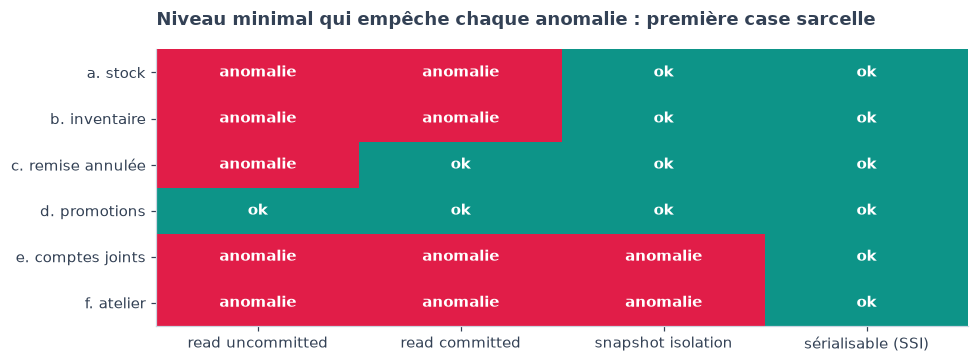

In [6]:
code = (diag[[LEVEL_LABELS[l] for l in ordre_niv]] == "ok").astype(int).values
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.imshow(code, cmap=plt.matplotlib.colors.ListedColormap([ROSE, TEAL]), aspect="auto")
for i in range(code.shape[0]):
    for j in range(code.shape[1]):
        ax.text(j, i, "ok" if code[i, j] else "anomalie", ha="center", va="center", color="white", fontweight="bold")
ax.set_xticks(range(4)); ax.set_xticklabels([LEVEL_LABELS[l] for l in ordre_niv])
ax.set_yticks(range(len(diag))); ax.set_yticklabels(diag.index)
ax.grid(False)
ax.set_title("Niveau minimal qui empêche chaque anomalie : première case sarcelle")
plt.tight_layout(); plt.show()

Le moteur confirme les six diagnostics, en « escalier » : d (écriture sale) est empêchée
dès *read uncommitted*, c (lecture sale) dès *read committed*, a et b par la snapshot
isolation, e et f seulement par le niveau sérialisable.

> **À retenir.** Pour diagnostiquer une anomalie, demandez-vous : lit-on du non-validé
> (sale) ? lit-on à des instants différents (biais) ? deux cycles lire-écrire sur le
> **même** objet (perdue) ? sur des objets **différents** à partir d'une même prémisse
> (write skew, fantôme) ?